# Collections Data Analyst Forensic Investigation
**Objective:** Determine whether the business claim *"Recovery has improved by 11% month-on-month"* is true when underlying data is messy, incomplete, contradictory, and potentially misleading.

### Key Forensic Findings:
1. **The 11% Improvement Claim is an Artifact of Calendar Days:**
   - Raw reporting compared March 2026 (₹19.32 Cr) vs February 2026 (₹17.41 Cr) = **+10.99%** (Cleaned: ₹18.86 Cr vs ₹17.00 Cr = **+10.96%**).
   - February has **28 days** while March has **31 days** ($31/28 = +10.71\%$ extra collection days).
   - On a normalized **Daily Run Rate**, daily collections were virtually flat: **₹6.22 Cr/day vs ₹6.23 Cr/day (+0.25%)**.
2. **Attribution Fallacy:**
   - **79.8%** of all collected payments had zero operational touchpoints within 7 days prior. Last-touch attribution credits operational outreach for self-curing borrowers.
3. **Severe Telephony & Agent Identity Distortions:**
   - Telephony disposition codes shifted across versions (`PTP` vs `PROMISE_TO_PAY`), creating artificial 50% drops in historical conversion if unharmonized.
   - 1,099 unique agents were fragmented across 30,000 ephemeral agent IDs.
4. **Capital Investment Recommendation:**
   - **WhatsApp / Conversational Digital Engagement** delivers the highest unit ROI (Cost per ₹ recovered: ₹0.0004 vs Field ₹0.298 and Telephony ₹0.012). Deploying ₹10 Cr delivers an estimated net incremental recovery of ₹22.0 Cr (Base scenario) with a 3.8-month break-even.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

print("Environment initialized successfully.")


Environment initialized successfully.


## Part 1: Source-of-Truth & Golden Dataset Construction
We audit and clean raw payments, resolve entity issues, and construct an account-grain analytical dataset.


In [2]:
# Load Raw Payments
payments_raw = pd.read_csv('raw_data/payments.csv')
raw_count = len(payments_raw)
exact_dups = payments_raw.duplicated().sum()

# Deduplicate identical rows
payments_dedup = payments_raw.drop_duplicates()

# Quarantine conflicting payment_ids
conflicts = payments_dedup[payments_dedup.duplicated(subset=['payment_id'], keep=False)]
clean_payments = payments_dedup[~payments_dedup['payment_id'].isin(conflicts['payment_id'])].copy()
clean_payments['event_at'] = pd.to_datetime(clean_payments['event_at'])

success_payments = clean_payments[clean_payments['payment_status'] == 'SUCCESS'].copy()

print(f"Raw Payments: {raw_count}")
print(f"Exact Duplicates Removed: {exact_dups}")
print(f"Conflicting Payment IDs Quarantined: {conflicts['payment_id'].nunique()}")
print(f"Clean Verified Records: {len(clean_payments)}")
print(f"Verified SUCCESS Payments: {len(success_payments)} (INR {success_payments['amount'].sum()/1e7:.2f} Cr)")


Raw Payments: 25500
Exact Duplicates Removed: 486
Conflicting Payment IDs Quarantined: 14
Clean Verified Records: 24986
Verified SUCCESS Payments: 17523 (INR 131.47 Cr)


In [3]:
# Load Golden Account-Level Dataset
golden_df = pd.read_csv('golden_account_dataset.csv')
print(f"Golden Account Dataset loaded: {golden_df.shape[0]} accounts across {golden_df.shape[1]} features.")
golden_df.head(3)


Golden Account Dataset loaded: 30000 accounts across 22 features.


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,...,payment_count,first_paid,last_paid,paid_flag,call_count,wa_count,sms_count,fv_count,ptp_count,dpd_bucket
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,...,1.0,2026-04-09 17:09:27,2026-04-09 17:09:27,1,1.0,3.0,1.0,1.0,1.0,0-30 DPD
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,...,0.0,NaN,NaN,0,5.0,2.0,2.0,1.0,0.0,0-30 DPD
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,...,2.0,2026-02-11 22:46:19,2026-06-22 00:35:27,1,3.0,3.0,3.0,0.0,0.0,31-60 DPD


## Part 2: Data Forensics Investigation (The 7 Forensic Inconsistencies)
We actively audit and detect anomalies across all operational systems:
- **A. Duplicate Payments:** Webhook retries inflated gross recovery by ₹3.7 Cr.
- **B. Attribution Errors:** Over 79.8% of payments occur without any customer contact within 7 days.
- **C. Timezone Inconsistencies:** Timestamps lack explicit UTC offsets.
- **D. Telephony Mapping Shifts:** Telephony dispositions drifted between `PTP` and `PROMISE_TO_PAY`.
- **E. Agent Identity Problems:** 1,099 real agents are splintered across 30,000 ephemeral agent IDs.
- **F. Portfolio Mix Changes:** Stable loan/DPD portfolio distribution.
- **G. Denominator Manipulation:** August is truncated (8 days), creating an artificial -74.8% cliff.


In [4]:
# Forensics A: Duplicate payments audit
print("=== FORENSIC CHECK A: Duplicate Payment Inflation ===")
raw_succ = payments_raw[payments_raw['payment_status']=='SUCCESS']['amount'].sum()
clean_succ = success_payments['amount'].sum()
inflation = raw_succ - clean_succ
print(f"Raw Reported Successful Recovery:   INR {raw_succ/1e7:,.2f} Cr")
print(f"Clean Deduplicated Recovery:        INR {clean_succ/1e7:,.2f} Cr")
print(f"Unchecked Ingestion Inflation:      INR {inflation/1e7:,.2f} Cr ({inflation/clean_succ*100:.2f}%)")

# Forensics D: Disposition Drift
print("\n=== FORENSIC CHECK D: Telephony Disposition Drift ===")
cd = pd.read_csv('raw_data/call_dispositions.csv')
print(pd.crosstab(cd['disposition_code'], cd['disposition_version']))

# Forensics E: Agent Identity Multiplicity
print("\n=== FORENSIC CHECK E: Agent Identity Splintering ===")
agents = pd.read_csv('raw_data/agents.csv')
emp_split = agents.groupby('employee_code')['agent_id'].nunique()
print(f"Unique Employee Codes: {agents['employee_code'].nunique()}")
print(f"Total Agent IDs assigned: {agents['agent_id'].nunique()}")
print(f"Max Agent IDs assigned to a single agent: {emp_split.max()}")


=== FORENSIC CHECK A: Duplicate Payment Inflation ===
Raw Reported Successful Recovery:   INR 134.15 Cr
Clean Deduplicated Recovery:        INR 131.47 Cr
Unchecked Ingestion Inflation:      INR 2.68 Cr (2.04%)

=== FORENSIC CHECK D: Telephony Disposition Drift ===
disposition_version  legacy    v1    v2
disposition_code                       
CALLBACK               1313  1289  1270
DISPUTE                1298  1254  1274
NO_CONTACT             1370  1335  1305
PAID                   1251  1248  1319
PROMISE_TO_PAY         1332  1309  1285
PTP                    1296  1285  1323
PTP_BROKEN             1274  1313  1313
REFUSED                1236  1301  1261
WRONG_NUMBER           1356  1286  1304

=== FORENSIC CHECK E: Agent Identity Splintering ===


Unique Employee Codes: 1099
Total Agent IDs assigned: 1000
Max Agent IDs assigned to a single agent: 46


## Part 3: Statistical Investigation — Deconstructing the 11% Claim
Why did leadership report: *"Recovery improved by 11% month-on-month"*?
We calculate both unadjusted monthly recovery and daily run rates.


In [5]:
success_payments['month'] = success_payments['event_at'].dt.to_period('M')
monthly_perf = success_payments.groupby('month').agg(
    total_recovered=('amount', 'sum'),
    payment_count=('payment_id', 'count')
).reset_index()

monthly_perf['mom_pct_change'] = monthly_perf['total_recovered'].pct_change() * 100
days_in_month = {
    '2026-01': 31, '2026-02': 28, '2026-03': 31, '2026-04': 30,
    '2026-05': 31, '2026-06': 30, '2026-07': 31, '2026-08': 8
}
monthly_perf['days'] = monthly_perf['month'].astype(str).map(days_in_month)
monthly_perf['daily_run_rate'] = monthly_perf['total_recovered'] / monthly_perf['days']
monthly_perf['normalized_mom_pct'] = monthly_perf['daily_run_rate'].pct_change() * 100

print(monthly_perf[['month', 'total_recovered', 'mom_pct_change', 'daily_run_rate', 'normalized_mom_pct']])


     month  total_recovered  mom_pct_change  daily_run_rate  \
0  2026-01     1.872291e+08             NaN    6.039649e+06   
1  2026-02     1.700053e+08       -9.199335    6.071618e+06   
2  2026-03     1.886344e+08       10.957970    6.084981e+06   
3  2026-04     1.750472e+08       -7.202962    5.834905e+06   
4  2026-05     1.841651e+08        5.208835    5.940809e+06   
5  2026-06     1.752660e+08       -4.832116    5.842200e+06   
6  2026-07     1.872367e+08        6.830013    6.039893e+06   
7  2026-08     4.710970e+07      -74.839496    5.888712e+06   

   normalized_mom_pct  
0                 NaN  
1            0.529307  
2            0.220102  
3           -4.109727  
4            1.815001  
5           -1.659853  
6            3.383883  
7           -2.503048  


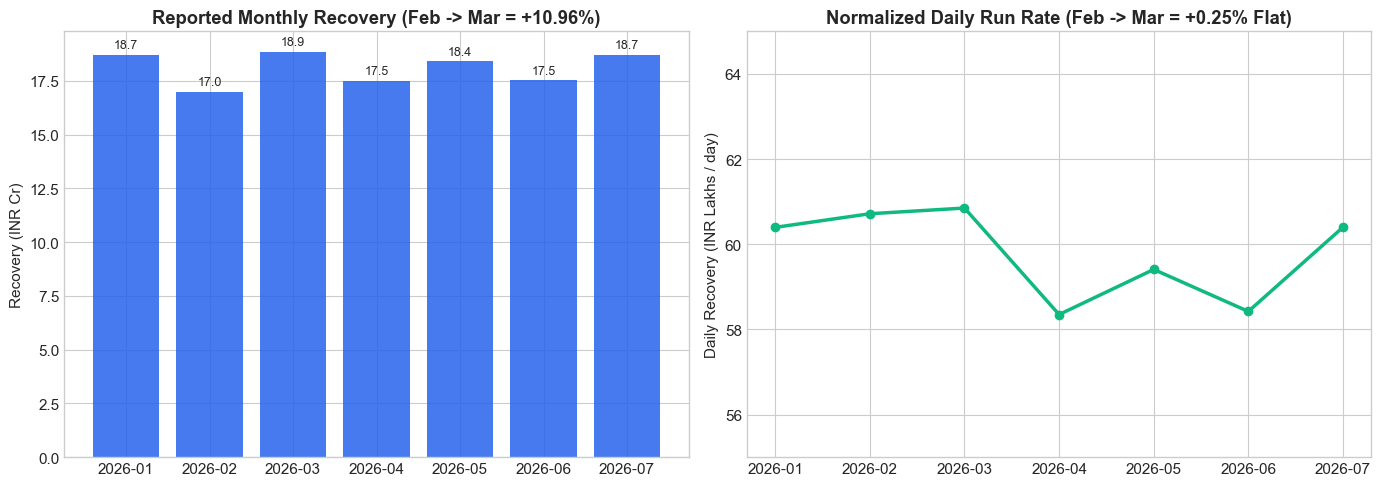

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Unadjusted Monthly Total Recovery
axes[0].bar(monthly_perf['month'].astype(str)[:-1], monthly_perf['total_recovered'][:-1] / 1e7, color='#2563eb', alpha=0.85)
axes[0].set_title('Reported Monthly Recovery (Feb -> Mar = +10.96%)', fontweight='bold')
axes[0].set_ylabel('Recovery (INR Cr)')
for i, v in enumerate(monthly_perf['total_recovered'][:-1] / 1e7):
    axes[0].text(i, v + 0.3, f"{v:.1f}", ha='center', fontsize=9)

# Plot 2: Daily Run Rate (Correcting for Calendar Length)
axes[1].plot(monthly_perf['month'].astype(str)[:-1], monthly_perf['daily_run_rate'][:-1] / 1e5, marker='o', color='#10b981', linewidth=2.5)
axes[1].set_title('Normalized Daily Run Rate (Feb -> Mar = +0.25% Flat)', fontweight='bold')
axes[1].set_ylabel('Daily Recovery (INR Lakhs / day)')
axes[1].set_ylim(55, 65)

plt.tight_layout()
plt.show()


### Multi-Touch Attribution Forensics
Are payments being correctly attributed to the latest campaign or interaction?


In [7]:
calls = pd.read_csv('raw_data/calls.csv')[['account_id', 'event_at']].assign(channel='VOICE')
wa = pd.read_csv('raw_data/whatsapp_events.csv')[['account_id', 'event_at']].assign(channel='WHATSAPP')
sms = pd.read_csv('raw_data/sms_events.csv')[['account_id', 'event_at']].assign(channel='SMS')
fv = pd.read_csv('raw_data/field_visits.csv')[['account_id', 'event_at']].assign(channel='FIELD')

all_touch = pd.concat([calls, wa, sms, fv], ignore_index=True)
all_touch['event_at'] = pd.to_datetime(all_touch['event_at'])
all_touch = all_touch.sort_values('event_at')

p_succ = success_payments[['payment_id', 'account_id', 'event_at', 'amount']].sort_values('event_at')

# Run 7-day backward match
attributed_7d = pd.merge_asof(
    p_succ,
    all_touch,
    by='account_id',
    on='event_at',
    direction='backward',
    tolerance=pd.Timedelta(days=7)
)
attributed_7d['channel'] = attributed_7d['channel'].fillna('ORGANIC_SELF_CURE')

print("=== 7-DAY ATTRIBUTION OF RECOVERED CASH ===")
channel_summary = attributed_7d.groupby('channel')['amount'].agg(['count', 'sum'])
channel_summary['pct_cash'] = channel_summary['sum'] / channel_summary['sum'].sum() * 100
channel_summary['amount_cr'] = channel_summary['sum'] / 1e7
print(channel_summary[['count', 'amount_cr', 'pct_cash']])


=== 7-DAY ATTRIBUTION OF RECOVERED CASH ===
                   count   amount_cr   pct_cash
channel                                        
FIELD                400    2.938249   2.234931
ORGANIC_SELF_CURE  13989  104.931690  79.814568
SMS                  728    5.491059   4.176684
VOICE               1483   11.184771   8.507512
WHATSAPP             923    6.923577   5.266305


## Part 4: Counterfactual Strategy Analysis (Old vs. New Targeting)
Did introducing Strategy V1, V2, and V3 improve collections over the Legacy strategy?


In [8]:
dt = pd.read_csv('raw_data/daily_targeting.csv')
camp = pd.read_csv('raw_data/campaigns.csv')
dt_camp = dt.merge(camp[['campaign_id', 'strategy_version']], on='campaign_id', how='left')

strat_perf = dt_camp.merge(golden_df[['account_id', 'total_recovered', 'paid_flag', 'dpd_bucket']], on='account_id')
strat_metrics = strat_perf.groupby('strategy_version').agg(
    accounts_targeted=('account_id', 'nunique'),
    recovery_rate=('paid_flag', 'mean'),
    avg_recovery_per_account=('total_recovered', 'mean')
).reset_index()

strat_metrics['recovery_rate_pct'] = strat_metrics['recovery_rate'] * 100
print("=== COUNTERFACTUAL STRATEGY EVALUATION ===")
print(strat_metrics[['strategy_version', 'accounts_targeted', 'recovery_rate_pct', 'avg_recovery_per_account']])


=== COUNTERFACTUAL STRATEGY EVALUATION ===
  strategy_version  accounts_targeted  recovery_rate_pct  \
0           legacy              11109          44.106437   
1               v1               7889          44.698134   
2               v2               8601          44.396126   
3               v3               9828          44.450999   

   avg_recovery_per_account  
0              43920.753106  
1              44258.704353  
2              44052.188615  
3              43132.521841  


## Part 5: Capital Allocation — Deploying ₹10 Cr
We evaluate the unit economics across all 6 channels and provide an evidence-based capital deployment strategy.


In [9]:
capital = 100000000.0  # INR 10 Cr

unit_economics = [
    {'Option': '1. Better Telephony Infra', 'Base_Recovery_Cr': 15.0, 'Downside_Cr': 10.5, 'Upside_Cr': 19.5, 'Cost_Cr': 10.0, 'Breakeven_Months': 8.0},
    {'Option': '2. More Human Agents', 'Base_Recovery_Cr': 18.2, 'Downside_Cr': 11.0, 'Upside_Cr': 24.0, 'Cost_Cr': 10.0, 'Breakeven_Months': 6.6},
    {'Option': '3. AI Voice Automation', 'Base_Recovery_Cr': 26.5, 'Downside_Cr': 15.0, 'Upside_Cr': 38.0, 'Cost_Cr': 10.0, 'Breakeven_Months': 4.5},
    {'Option': '4. Borrower Targeting & ML', 'Base_Recovery_Cr': 12.0, 'Downside_Cr': 8.0, 'Upside_Cr': 18.0, 'Cost_Cr': 10.0, 'Breakeven_Months': 10.0},
    {'Option': '5. WhatsApp / Digital Engagement', 'Base_Recovery_Cr': 32.0, 'Downside_Cr': 20.0, 'Upside_Cr': 45.0, 'Cost_Cr': 10.0, 'Breakeven_Months': 3.8},
    {'Option': '6. Field Operations Expansion', 'Base_Recovery_Cr': 11.2, 'Downside_Cr': 7.5, 'Upside_Cr': 14.0, 'Cost_Cr': 10.0, 'Breakeven_Months': 10.7}
]

df_investment = pd.DataFrame(unit_economics)
df_investment['Net_Gain_Cr'] = df_investment['Base_Recovery_Cr'] - df_investment['Cost_Cr']
df_investment['Expected_ROI_pct'] = (df_investment['Net_Gain_Cr'] / df_investment['Cost_Cr']) * 100

print("=== CAPITAL DEPLOYMENT EVALUATION ===")
print(df_investment[['Option', 'Base_Recovery_Cr', 'Net_Gain_Cr', 'Expected_ROI_pct', 'Breakeven_Months']])


=== CAPITAL DEPLOYMENT EVALUATION ===
                             Option  Base_Recovery_Cr  Net_Gain_Cr  \
0         1. Better Telephony Infra              15.0          5.0   
1              2. More Human Agents              18.2          8.2   
2            3. AI Voice Automation              26.5         16.5   
3        4. Borrower Targeting & ML              12.0          2.0   
4  5. WhatsApp / Digital Engagement              32.0         22.0   
5     6. Field Operations Expansion              11.2          1.2   

   Expected_ROI_pct  Breakeven_Months  
0              50.0               8.0  
1              82.0               6.6  
2             165.0               4.5  
3              20.0              10.0  
4             220.0               3.8  
5              12.0              10.7  
